In [1]:
%load_ext byname

In [2]:
import math
import time
from typing import TYPE_CHECKING

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from einops import rearrange
from matplotlib.axes import Axes
from torch import Tensor, nn
from torchvision.utils import make_grid

from data import get_batch, split


In [3]:
(train_data=, val_data=) = split()
train_data.images.shape, val_data.images.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([10000, 1, 28, 28]))

In [4]:
x, y = get_batch(train_data, batch_size=2)
x.shape, y.shape

(torch.Size([2, 1, 28, 28]), torch.Size([2]))

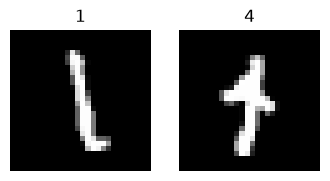

In [5]:
# x: [B, 1, 28, 28] in [-1, 1]; vmin/vmax pin -1 to black and 1 to white
fig, axes = plt.subplots(1, len(x), figsize=(2 * len(x), 2), squeeze=False)
ax: Axes
for ax, img, label in zip(axes[0], x, y):
    ax.imshow(img[0], cmap="gray", vmin=-1, vmax=1)  # [28, 28]
    ax.set_title(f"{label.item()}")
    ax.axis("off")
plt.show()

In [6]:
def interpolate(x0: Tensor, noise: Tensor, t: Tensor) -> Tensor:
    # x0, noise: [B, C, H, W], t: [B]
    # out: [B, C, H, W], each image t[b] of the way from its x0 to its noise
    t = rearrange(t, "B -> B 1 1 1")  # broadcasts over the pixels
    return (1 - t) * x0 + t * noise


In [7]:
(images=, labels=) = train_data
x0 = images[:1]
label = labels[:1]
x0.shape, label, x0.min(), x0.max()

(torch.Size([1, 1, 28, 28]), tensor([5]), tensor(-1.), tensor(1.))

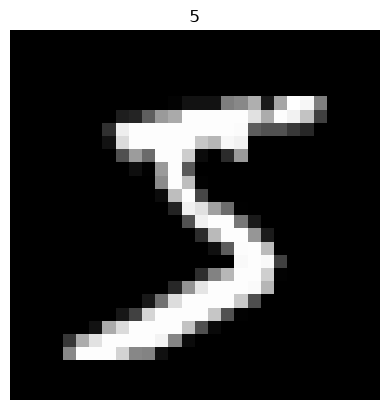

In [8]:
plt.imshow(x0[0, 0], cmap="gray", vmin=-1, vmax=1)
plt.title(f"{label.item()}")
plt.axis("off")
plt.show()

In [9]:
noise = torch.randn_like(x0)
print("t=0 is data: ", torch.equal(interpolate(x0, noise, torch.zeros(1)), x0))
print("t=1 is noise:", torch.equal(interpolate(x0, noise, torch.ones(1)), noise))

t=0 is data:  True
t=1 is noise: True


In [10]:
def sample_t(
    n: int,
    *,
    device: str | torch.device = "cpu",
    generator: torch.Generator | None = None,
) -> Tensor:
    # out: [n], uniform on [0, 1), continuous; every point on the path is trained
    return torch.rand(n, device=, generator=)


sample_t(10)

tensor([0.1959, 0.5369, 0.7232, 0.3873, 0.5218, 0.1449, 0.9109, 0.9389, 0.1091,
        0.1405])

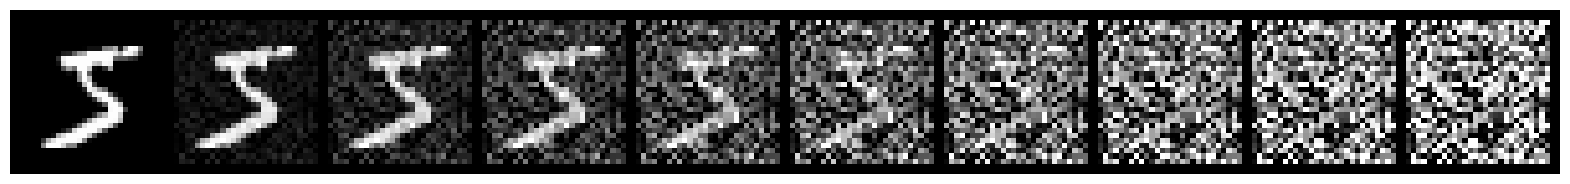

In [11]:
B = 10
x0b = x0.expand(B, -1, -1, -1)  # [B, 1, 28, 28], the same digit B times
noise_b = torch.randn_like(x0).expand(B, -1, -1, -1)  # one noise, shared across t
t = torch.linspace(0, 1, B)  # [B]
r = interpolate(x0b, noise_b, t)  # [B, 1, 28, 28]

grid = make_grid(r, nrow=B, normalize=True, value_range=(-1, 1))  # [3, H, W]
plt.figure(figsize=(20, 3))
plt.imshow(rearrange(grid, "c h w -> h w c"))
plt.axis("off")
plt.show()


In [12]:
TIME_SCALE = 1000.0
MAX_PERIOD = 10000.0


def time_embedding(t: Tensor, dim: int) -> Tensor:
    # t: [B], flow time in [0, 1]
    # out: [B, dim], sin of dim/2 frequencies then cos of the same
    # the transformer's position encoding, applied to a time instead of a position.
    # frequencies are geometric from 1 down to 1/MAX_PERIOD, so fast channels tell
    # nearby t apart and slow ones place t on the whole range
    assert dim % 2 == 0, f"time embedding dim {dim} is odd, but sin and cos pair up"
    half = dim // 2
    i = torch.arange(half, device=t.device, dtype=torch.float32)  # [dim/2]
    freqs = torch.exp(-math.log(MAX_PERIOD) * i / half)  # [dim/2], 1 -> ~1/MAX_PERIOD
    angles = rearrange(t.float() * TIME_SCALE, "B -> B 1") * freqs  # [B, dim/2]
    return torch.cat([angles.sin(), angles.cos()], dim=1)  # [B, dim]


In [13]:
class TinyDenoiser(nn.Module):
    # (x_t, t) -> v, same shape as x_t. three convs, no down/up sampling;
    # t enters once, as a per-channel shift after the first conv
    def __init__(self, channels: int = 64, time_dim: int = 64):
        super().__init__()
        self.time_dim = time_dim
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, channels),
        )
        self.conv_in = nn.Conv2d(1, channels, 3, padding=1)
        self.conv_mid = nn.Conv2d(channels, channels, 3, padding=1)
        self.conv_out = nn.Conv2d(channels, 1, 3, padding=1)
        self.act = nn.SiLU()

    def forward(self, x: Tensor, t: Tensor) -> Tensor:
        # x: [B, 1, 28, 28], t: [B]
        # out: [B, 1, 28, 28]
        emb: Tensor = self.time_mlp(time_embedding(t, self.time_dim))  # [B, C]
        h: Tensor = self.conv_in(x)  # [B, C, 28, 28]
        h = self.act(h + rearrange(emb, "B C -> B C 1 1"))  # same shift at every pixel
        h = self.act(self.conv_mid(h))  # [B, C, 28, 28]
        return self.conv_out(h)  # [B, 1, 28, 28]

    # nn.Module types model(x) as Any; checker-only, keep in step with forward
    if TYPE_CHECKING:

        def __call__(self, x: Tensor, t: Tensor) -> Tensor: ...


In [14]:
model = TinyDenoiser()
x_t = interpolate(x0b, noise_b, t)  # [B, 1, 28, 28]
v = model(x_t, t)  # [B, 1, 28, 28]
x_t.shape, v.shape, sum(p.numel() for p in model.parameters())


(torch.Size([10, 1, 28, 28]), torch.Size([10, 1, 28, 28]), 46465)

In [15]:
def train_tiny(
    model: TinyDenoiser, *, steps: int, batch_size: int = 128, lr: float = 2e-4,
    log_every: int = 500, device: str | torch.device = "cpu",
) -> None:
    # random batches from get_batch, so steps instead of epochs:
    # 469 steps of 128 is about one pass over the 60k train images
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    start, total = time.time(), 0.0
    for step in range(steps):
        x0, _ = get_batch(train_data, batch_size=, device=)  # [B, 1, 28, 28]
        noise = torch.randn_like(x0)  # [B, 1, 28, 28]
        t = sample_t(batch_size, device=)  # [B]
        x_t = interpolate(x0, noise, t)  # [B, 1, 28, 28]
        # d/dt of (1 - t) * x0 + t * noise, the same at every t
        target = noise - x0  # [B, 1, 28, 28]

        loss = F.mse_loss(model(x_t, t), target)
        opt.zero_grad()
        loss.backward()
        opt.step()

        total += loss.item()
        if (step + 1) % log_every == 0:
            print(
                f"step {step + 1}  loss {total / log_every:.4f}  {time.time() - start:.1f}s"
            )
            start, total = time.time(), 0.0


device = "cuda" if torch.cuda.is_available() else "cpu"
model = TinyDenoiser().to(device)
train_tiny(model, steps=1500, device=)


step 500  loss 0.6560  3.8s
step 1000  loss 0.3759  3.7s
step 1500  loss 0.3221  3.6s


range [-1.23, 1.70]  mean -0.763  std 0.558


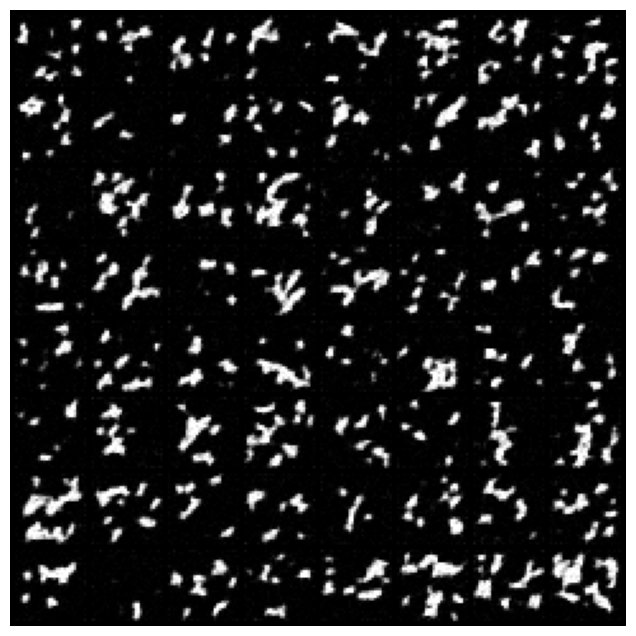

In [16]:
@torch.no_grad()
def sample(model: TinyDenoiser, n: int = 64, steps: int = 50) -> Tensor:
    # x: [n, 1, 28, 28] noise at t = 1, fresh if None
    # out: [n, 1, 28, 28], Euler steps of dx/dt = v from t = 1 down to t = 0
    ts = torch.linspace(1, 0, steps + 1, device=device)  # [steps + 1]
    x = torch.randn(n, 1, 28, 28, device=device)
    for i in range(steps):
        t = ts[i].expand(x.shape[0])  # [n]
        dt = ts[i + 1] - ts[i]  # negative: walking back to the data
        x = x + dt * model(x, t)
    return x


s = sample(model, 64, steps=50)  # [64, 1, 28, 28]
print(f"range [{s.min():.2f}, {s.max():.2f}]  mean {s.mean():.3f}  std {s.std():.3f}")

plt.figure(figsize=(8, 8))
plt.imshow(
    make_grid(s.cpu(), nrow=8, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)
)
plt.axis("off")
plt.show()
